# Chapitre 4 - Cours 5 : flux de données par les services, REST et RPC

Deuxième mode de flux de données : des processus qui se parlent **directement** par le
réseau, un client envoyant des requêtes à un serveur. Ce cours construit un vrai petit
service HTTP en local pour mesurer ce que coûte un appel distant, montre pourquoi un
appel réseau n'est **pas** un appel de fonction, puis étudie l'évolution des API. Il
couvre la section *Dataflow Through Services: REST and RPC* (*Web services*, *The problems
with remote procedure calls*, *Current directions for RPC*, *Data encoding and evolution for RPC*).

**Plan.**

1. Clients, serveurs et services.
2. Les services web et REST, en vrai sur la machine.
3. Les problèmes des appels de procédure distants : latence, délais, relances.
4. L'évolution des API : qui doit être compatible avec qui ?


In [1]:
import json
import threading
import time
import urllib.error
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle, SEQ)
from ddia.sim import Network, Node
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Clients, serveurs et services (section *Dataflow Through Services: REST and RPC*)

La façon la plus courante de faire communiquer des processus par le réseau distingue deux
rôles : des **serveurs** exposent une API, des **clients** s'y connectent pour faire des
requêtes. L'API exposée s'appelle un **service**. Le web fonctionne ainsi : le navigateur
envoie des requêtes `GET` (pages, images, scripts) et `POST` (formulaires) à des serveurs,
selon des standards communs (HTTP, URL, TLS, HTML). Les applications mobiles et le
JavaScript exécuté dans le navigateur font aussi des requêtes HTTP, mais reçoivent des
**données** (souvent du JSON) plutôt que du HTML à afficher.

Un service ressemble à une base (on y soumet et on y interroge des données), avec une
différence : une base accepte des requêtes arbitraires dans un langage de requête, un
service n'expose qu'une API **prédéfinie** par sa logique métier. Cette restriction est
une **encapsulation** : le service contrôle finement ce que les clients peuvent faire.

Une architecture orientée services (ou **microservices**) vise à rendre l'application
plus facile à faire évoluer, en rendant chaque service **déployable indépendamment** par
l'équipe qui le possède, sans coordination avec les autres. Il faut donc s'attendre à ce
que d'anciennes et de nouvelles versions de serveurs et de clients tournent en même temps.

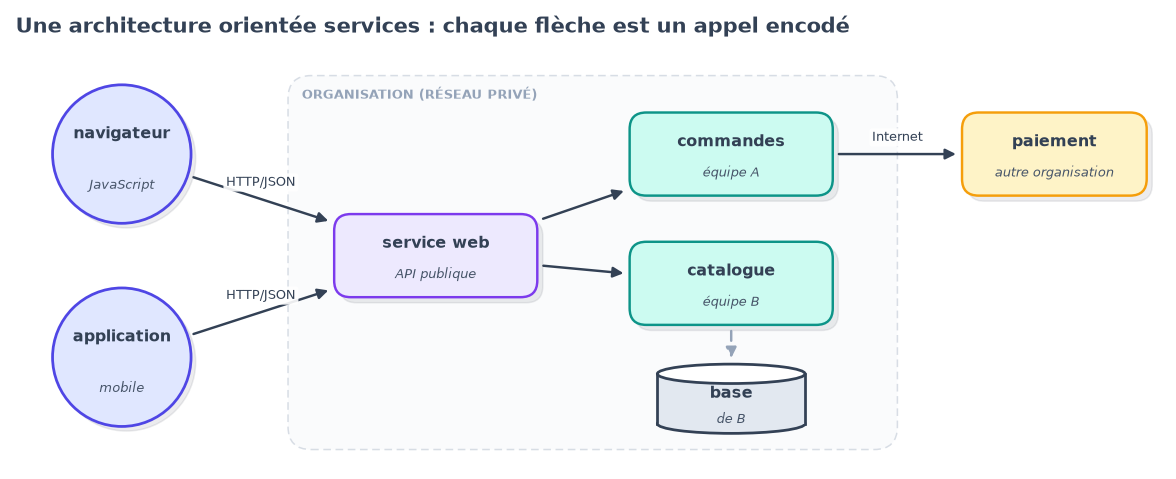

In [2]:
d = Diagram(12.5, 4.4, title="Une architecture orientée services : chaque flèche est un appel encodé")
d.box("nav", 1.2, 3.4, "navigateur", sub="JavaScript", color=INDIGO, kind="user", w=1.5)
d.box("mob", 1.2, 1.2, "application", sub="mobile", color=INDIGO, kind="user", w=1.5)
d.group(3.0, 0.2, 9.6, 4.25, "organisation (réseau privé)", color=GRAY)
d.box("web", 4.6, 2.3, "service web", sub="API publique", color=VIOLET, w=2.2)
d.box("cmd", 7.8, 3.4, "commandes", sub="équipe A", color=TEAL, w=2.2)
d.box("cat", 7.8, 2.0, "catalogue", sub="équipe B", color=TEAL, w=2.2)
d.box("db1", 7.8, 0.75, "base", sub="de B", color=SLATE, kind="db", w=1.6, h=0.75)
d.box("pay", 11.3, 3.4, "paiement", sub="autre organisation", color=AMBER, w=2.0)
d.arrow("nav", "web", "HTTP/JSON")
d.arrow("mob", "web", "HTTP/JSON")
d.arrow("web", "cmd")
d.arrow("web", "cat")
d.arrow("cat", "db1", style="dashed", color=GRAY)
d.arrow("cmd", "pay", "Internet")
d.show()

> **À retenir.** Un service expose une API prédéfinie par le réseau ; le client encode la
> requête, le serveur la décode, encode la réponse, et le client la décode. Les services
> sont déployés indépendamment : versions anciennes et nouvelles coexistent.

## 2. Les services web et REST (section *Web services*)

On parle de **service web** quand le protocole sous-jacent est HTTP, même hors du web :
une application mobile qui appelle un serveur par Internet, deux services d'une même
organisation dans un réseau privé, ou deux organisations qui échangent des données (API
publiques de paiement, OAuth pour partager l'accès à des données).

La philosophie la plus répandue est **REST**, qui s'appuie sur les principes de HTTP :
des formats de données simples, des URL pour identifier des **ressources**, et les
mécanismes de HTTP pour le cache, l'authentification et la négociation du type de
contenu. Construisons un vrai petit service REST avec la bibliothèque standard : une
ressource `/clients/<id>` (lecture `GET`, écriture `PUT`) et une ressource `/paiements`
(`POST`), qui tourne dans un fil d'exécution sur la boucle locale de la machine.

Le livre oppose REST à **SOAP**, un protocole fondé sur XML qui cherche à être
indépendant de HTTP et s'accompagne d'une pile complexe de normes (WS-*). Une API SOAP se
décrit dans un langage XML, WSDL, qui permet de générer le code client ; mais les
messages sont trop complexes pour être écrits à la main, l'interopérabilité entre
fournisseurs est souvent décevante, et SOAP a reculé au profit de REST hors des grandes
entreprises. Pour décrire une API REST, on peut utiliser un format comme OpenAPI (aussi
appelé Swagger), qui produit la documentation.

In [3]:
class Etat:
    clients = {1: {"id": 1, "nom": "Ana", "ville": "Lyon"}}
    paiements = []            # effets de bord réels (débits)
    deja_vus = {}             # clé d'idempotence -> réponse mémorisée
    en_cours = set()          # clés réservées dont le traitement n'est pas fini
    reserver = False          # réserver la clé dès la réception ?
    lenteur = 0.0             # délai artificiel du prochain paiement (secondes)
    verrou = threading.Lock()

class Handler(BaseHTTPRequestHandler):
    def log_message(self, *args):          # silence
        pass

    def _repondre(self, code, obj):
        corps = json.dumps(obj).encode()
        self.send_response(code)
        self.send_header("Content-Type", "application/json")
        self.send_header("Content-Length", str(len(corps)))
        self.end_headers()
        try:
            self.wfile.write(corps)
        except BrokenPipeError:            # le client a abandonné : la réponse se perd
            pass

    def do_GET(self):
        if self.path == "/ping":
            return self._repondre(200, {"message": "pong"})
        if self.path.startswith("/clients/"):
            c = Etat.clients.get(int(self.path.split("/")[2]))
            return self._repondre(200, c) if c else self._repondre(404, {"erreur": "inconnu"})
        self._repondre(404, {"erreur": "ressource inconnue"})

    def do_PUT(self):
        cid = int(self.path.split("/")[2])
        doc = json.loads(self.rfile.read(int(self.headers["Content-Length"])))
        Etat.clients[cid] = {**doc, "id": cid}
        self._repondre(200, Etat.clients[cid])

    def do_POST(self):
        doc = json.loads(self.rfile.read(int(self.headers["Content-Length"])))
        cle = self.headers.get("Idempotency-Key")
        with Etat.verrou:
            if cle and cle in Etat.deja_vus:
                return self._repondre(200, Etat.deja_vus[cle])
            if cle and Etat.reserver:
                if cle in Etat.en_cours:                 # doublon pendant le traitement
                    return self._repondre(409, {"erreur": "traitement en cours, réessayez"})
                Etat.en_cours.add(cle)
            lent, Etat.lenteur = Etat.lenteur, 0.0
        time.sleep(lent)                           # serveur momentanément lent
        with Etat.verrou:
            Etat.paiements.append(doc["montant"])
            rep = {"paiement": len(Etat.paiements), "montant": doc["montant"]}
            if cle:
                Etat.deja_vus[cle] = rep
                Etat.en_cours.discard(cle)
        self._repondre(201, rep)

ThreadingHTTPServer.request_queue_size = 128                     # file de connexions en attente
serveur = ThreadingHTTPServer(("127.0.0.1", 0), Handler)       # port choisi par le système
threading.Thread(target=serveur.serve_forever, daemon=True).start()
BASE = f"http://127.0.0.1:{serveur.server_address[1]}"

def appel(methode, chemin, corps=None, timeout=2.0, entetes=None):
    data = json.dumps(corps).encode() if corps is not None else None
    req = urllib.request.Request(BASE + chemin, data=data, method=methode,
                                 headers={"Content-Type": "application/json", **(entetes or {})})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return r.status, json.loads(r.read())

print(appel("GET", "/clients/1"))
print(appel("PUT", "/clients/2", {"nom": "Bob", "ville": "Lille"}))
print(appel("GET", "/clients/2"))

(200, {'id': 1, 'nom': 'Ana', 'ville': 'Lyon'})
(200, {'nom': 'Bob', 'ville': 'Lille', 'id': 2})
(200, {'nom': 'Bob', 'ville': 'Lille', 'id': 2})


Le client encode un document JSON, l'envoie dans une requête HTTP ; le serveur le décode,
applique sa logique, encode la réponse. Les deux côtés doivent s'accorder sur les URL,
les méthodes et le format des documents : c'est le **contrat** de l'API.

> **À retenir.** REST utilise HTTP tel quel : ressources désignées par des URL, méthodes
> HTTP, formats simples (JSON). Une description formelle de l'API sert de contrat, de
> documentation et de base à la génération de code.